# Mathematical feature creation

This notebook creates new house features with simple mathematical operations: sums, products, counts, means, and standard deviations. The goal is not to create columns randomly; it is to express quantities that have a clear interpretation.

## Example questions

- What is the total finished living area?
- How many area components are present?
- What is the average size of the main floor and basement?
- How variable are the floor areas?

These derived quantities can be easier for a model to use than several separate raw measurements.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid',context='notebook')

candidates=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('houseprice.csv')]
path=next((p for p in candidates if p.exists()),None)
if path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(path,na_values=['NA'])
print('Source:',path)
print('Shape:',data.shape)
display(data.head())

Source: ../imputation/houseprice.csv
Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Select source columns

The Ames data contains several area measurements. We use a small, interpretable subset. Missing values are filled with zero only for components where a missing value means that the component is absent; this assumption should be verified from the data dictionary.

In [2]:
area_columns=['GrLivArea','TotalBsmtSF','1stFlrSF','2ndFlrSF','GarageArea']
area=data[area_columns].copy().fillna(0)
display(area.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
GrLivArea,1460.0,1515.46,525.48,334.0,1129.50,1464.0,1776.75,5642.0
TotalBsmtSF,1460.0,1057.43,438.71,0.0,795.75,991.5,1298.25,6110.0
1stFlrSF,1460.0,1162.63,386.59,334.0,882.00,1087.0,1391.25,4692.0
2ndFlrSF,1460.0,346.99,436.53,0.0,0.00,0.0,728.00,2065.0
GarageArea,1460.0,472.98,213.80,0.0,334.50,480.0,576.00,1418.0


## 2. Create sums, products, counts, means, and spread

Each formula has a plain-language meaning. Count uses the original missingness before filling, so it tells us how many components were actually recorded. Product demonstrates a useful pattern such as quantity multiplied by unit price; for house data, multiplication is used cautiously because area products can be difficult to interpret.

In [3]:
created=pd.DataFrame(index=data.index)
created['total_finished_area']=area['GrLivArea']+area['TotalBsmtSF']
created['total_floor_area']=area['1stFlrSF']+area['2ndFlrSF']
created['average_selected_area']=area[['GrLivArea','TotalBsmtSF','1stFlrSF','2ndFlrSF']].mean(axis=1)
created['area_variability']=area[['GrLivArea','TotalBsmtSF','1stFlrSF','2ndFlrSF']].std(axis=1).fillna(0)
created['area_component_count']=data[area_columns].notna().sum(axis=1)
created['living_x_garage_area']=area['GrLivArea']*area['GarageArea']
display(created.head())
display(created.describe().T.round(2))

,total_finished_area,total_floor_area,average_selected_area,area_variability,area_component_count,living_x_garage_area
0,2566,1710,1069.00,427.334373,5,937080
1,2524,1262,946.50,631.000000,5,580520
2,2706,1786,1123.00,442.732425,5,1085888
3,2473,1717,1047.50,456.675304,5,1102314
4,3343,2198,1385.25,543.566233,5,1837528


,count,mean,std,min,25%,50%,75%,max
total_finished_area,1460.0,2572.89,823.60,334.00,2014.00,2479.00,3008.50,11752.00
total_floor_area,1460.0,1509.62,521.16,334.00,1123.75,1458.00,1775.25,5642.00
average_selected_area,1460.0,1020.63,326.58,167.00,792.00,985.38,1192.12,4348.50
area_variability,1460.0,574.21,193.93,192.83,432.00,536.34,682.69,2341.21
area_component_count,1460.0,5.00,0.00,5.00,5.00,5.00,5.00,5.00
living_x_garage_area,1460.0,769440.12,561496.77,0.00,398006.25,657260.00,975744.00,8000356.00


## 3. Inspect the new distributions

A feature may have a useful formula but still be highly skewed or dominated by a few records. Histograms and boxplots help us identify transformations or outlier treatment that may be needed later.

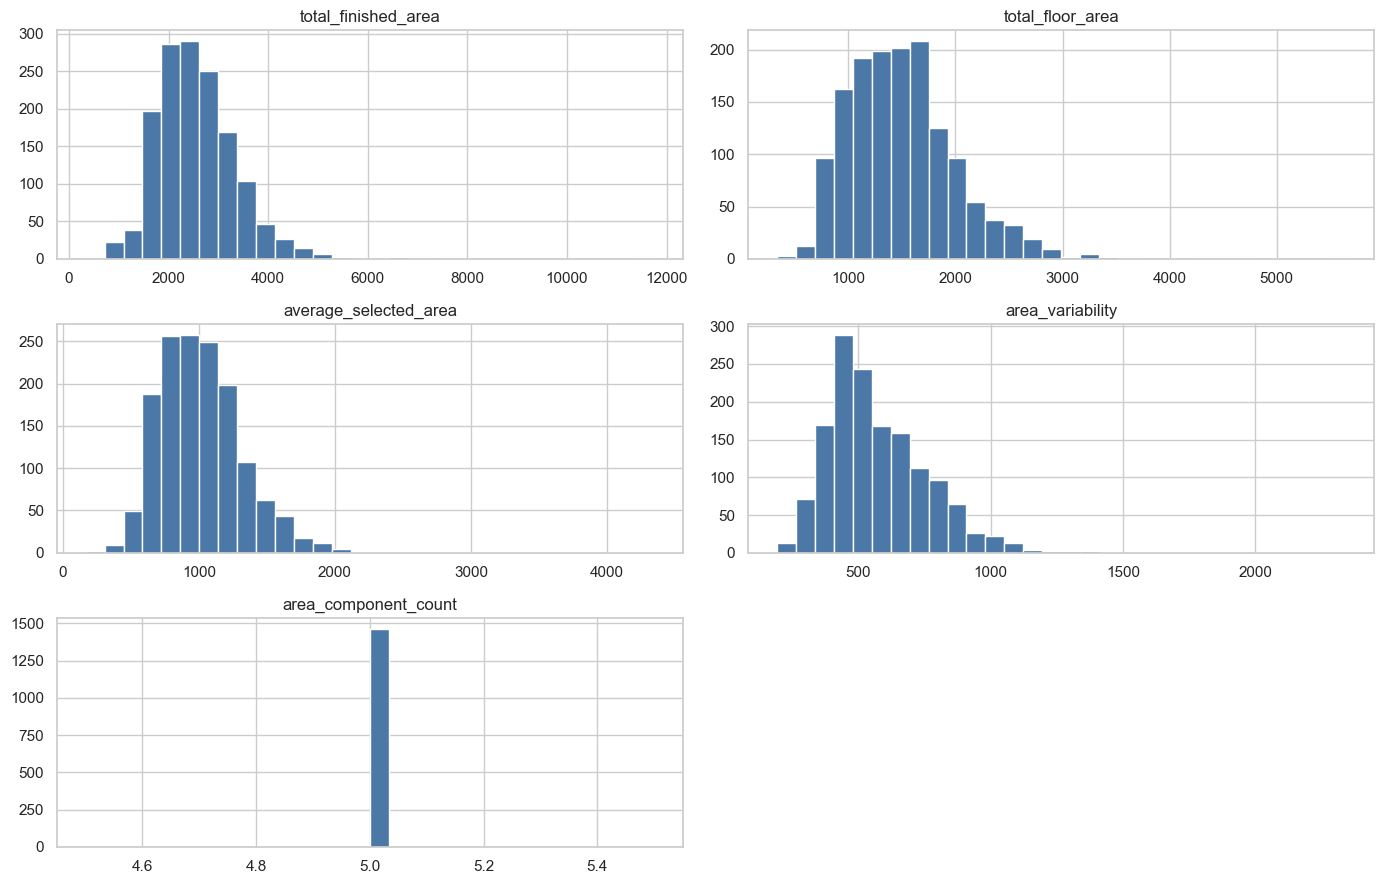

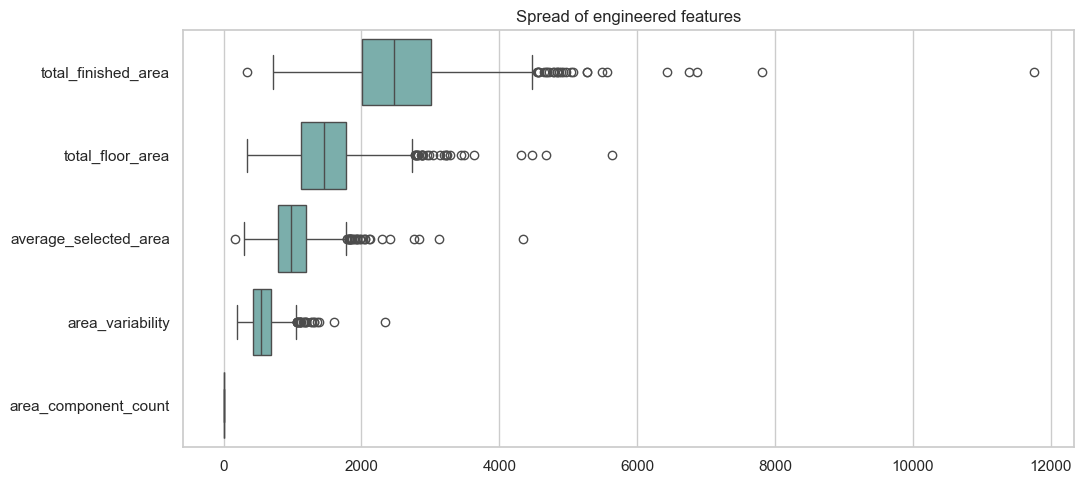

In [4]:
plot_columns=['total_finished_area','total_floor_area','average_selected_area','area_variability','area_component_count']
created[plot_columns].hist(bins=30,figsize=(14,9),color='#4C78A8'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,5)); sns.boxplot(data=created[plot_columns],orient='h',color='#72B7B2'); plt.title('Spread of engineered features'); plt.tight_layout(); plt.show()

## 4. Compare created features with the target

The target is used here for exploration only. In a modelling workflow, the formulas are created from X and the target remains separate. Correlation is not causation and should not replace cross-validation.

,correlation
SalePrice,1.000000
total_finished_area,0.778959
average_selected_area,0.777123
living_x_garage_area,0.751864
total_floor_area,0.716883
area_variability,0.575307
area_component_count,NaN


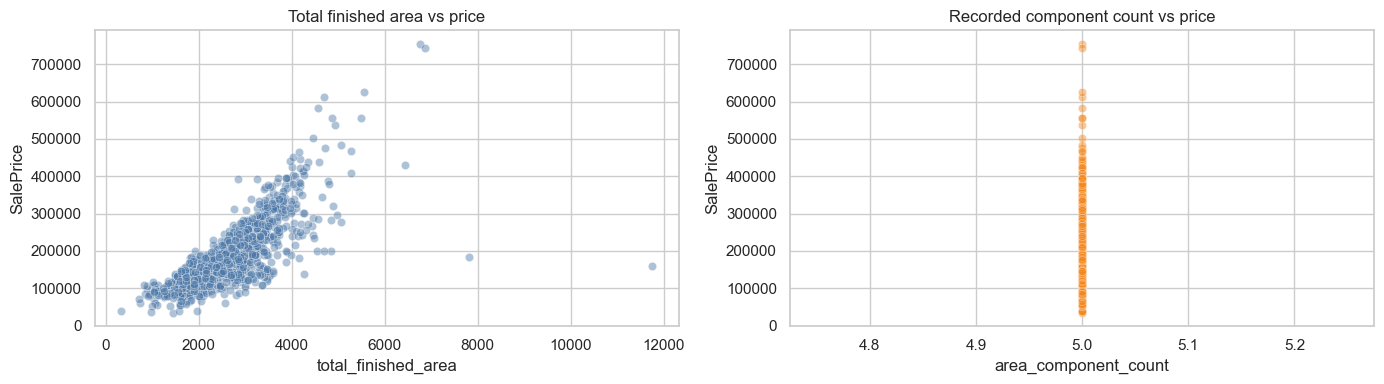

In [5]:
analysis=pd.concat([created,data[['SalePrice']]],axis=1)
display(analysis.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False).to_frame('correlation'))
fig,axes=plt.subplots(1,2,figsize=(14,4))
sns.scatterplot(data=analysis,x='total_finished_area',y='SalePrice',alpha=.45,color='#4C78A8',ax=axes[0]); axes[0].set_title('Total finished area vs price')
sns.scatterplot(data=analysis,x='area_component_count',y='SalePrice',alpha=.45,color='#F58518',ax=axes[1]); axes[1].set_title('Recorded component count vs price')
plt.tight_layout(); plt.show()

## 5. Quality checks

Check units, non-negativity, missingness, and the possibility of overflow or extreme products. A mathematical operation is only a good feature when its values remain meaningful.

In [6]:
assert created['total_finished_area'].ge(0).all()
assert created['total_floor_area'].ge(0).all()
assert created['area_component_count'].between(0,len(area_columns)).all()
assert np.isfinite(created.to_numpy()).all()
print('Feature checks passed.')
print('Created columns:',created.columns.tolist())

Feature checks passed.
Created columns: ['total_finished_area', 'total_floor_area', 'average_selected_area', 'area_variability', 'area_component_count', 'living_x_garage_area']


## Summary

Sums and aggregates can turn several raw measurements into a feature that matches the business question. Keep the formula documented, validate its edge cases, and compare it with the original columns rather than assuming the combination will improve a model.